# ☀️ Sistem Prediksi Musim Kemarau Beresolusi Tinggi Tingkat Kecamatan di Kabupaten Kebumen
### *Benchmark Kompetitif Terhadap Prakiraan Regional Zona Musim (ZOM) BMKG Menggunakan Deep Learning Sekuensial (LSTM / Bi-LSTM / GRU) & Spatial Downscaling Topografi 250m*

---

## 📌 Latar Belakang & Urgensi Riset
Prakiraan Awal Musim Kemarau (AMK) yang akurat dan beresolusi tinggi di tingkat kecamatan merupakan instrumen krusial bagi ketahanan pangan, manajemen irigasi waduk (seperti Waduk Sempor dan Waduk Wadaslintang), serta peringatan dini bencana kekeringan meteorologis dan hidrologis di Kabupaten Kebumen.

Prakiraan operasional BMKG berbasis pada **Zona Musim (ZOM)** makro, di mana 26 kecamatan di Kebumen sering kali digeneralisasi dalam 1–2 nilai prakiraan tunggal. Padahal, Kabupaten Kebumen memiliki kontras fisiografis yang sangat tajam:
1. **Zona Pesisir Urutsewu (Ambal, Mirit, Bonorowo):** Mengalami awal kemarau paling dini (**April III**) dengan akumulasi hujan kemarau paling rendah (< 500 mm) dan evapotranspirasi tinggi akibat hembusan angin tenggara Samudra Hindia.
2. **Zona Dataran Aluvial Tengah (19 Kecamatan):** Sentra produksi padi sawah irigasi teknis dengan waktu normal kemarau jatuh pada **Mei II**.
3. **Zona Perbukitan & Pegunungan Utara (Karanggayam, Karangsambung, Sadang):** Retensi kelembapan tinggi dan topografi terjal menahan sisa hujan monsun hingga **Mei III s/d Juni I** dengan akumulasi hujan kemarau mencapai > 850 mm.

Notebook ini mendokumentasikan:
- **Baseline Normal Klimatologi AMK 26 Kecamatan (2000–2025)** berdasarkan kriteria operasional BMKG ($P < 50	ext{ mm/dasarian}$).
- **Deep Learning Sekuensial Multi-Head (LSTM / Bi-LSTM / GRU):** Memodelkan dinamika temporal pra-kemarau 12 dasarian (Januari I – April III) dengan validasi ketat **Leave-One-Year-Out (LOYO 2000–2025, 676 out-of-fold samples)** tanpa kebocoran data.
- **Spatial Downscaling Topografi 250m:** Menghasilkan grid spasial kontinyu 250m berbasis DEM 30m Kebumen, elevasi, lereng, orientasi aspek, jarak ke garis pantai, dan TPI yang dikalibrasi dengan **Pelestarian Konservasi Massa Regional (Rule 15)**.
- **10 Peta Tematik Standar Publikasi 16:9 (300 DPI)** untuk diseminasi sektoral pertanian, mitigasi bencana BPBD, dan panduan pola tanam Palawija MT3.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, confusion_matrix
from IPython.display import Image, display

# Setup path direktori proyek
BASE_DIR = Path(r"d:\Github\Projek_Downscale")
DATA_DIR = BASE_DIR / "prediksi_musim" / "data"
PLOTS_DIR = BASE_DIR / "prediksi_musim" / "prediksi_musim_kemarau"
RASTER_DIR = BASE_DIR / "prediksi_musim" / "rasters_kemarau_250m"
GEOJSON_PATH = BASE_DIR / "33.05_kecamatan.geojson"

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✅ Library geospasial & deep learning berhasil dimuat.")
print(f"Direktori Data: {DATA_DIR}")
print(f"Direktori Plot 16:9: {PLOTS_DIR}")


✅ Library geospasial & deep learning berhasil dimuat.
Direktori Data: d:\Github\Projek_Downscale\prediksi_musim\data
Direktori Plot 16:9: d:\Github\Projek_Downscale\prediksi_musim\prediksi_musim_kemarau


## 1. Baseline Normal Klimatologi Awal Musim Kemarau (AMK) 26 Kecamatan (2000–2025)
Sesuai standar operasional BMKG, **Awal Musim Kemarau (AMK)** ditetapkan apabila:
- Suatu dasarian memiliki curah hujan $< 50	ext{ mm}$, dan
- Diikuti oleh $\ge 2$ dasarian berikutnya yang juga konsisten $< 50	ext{ mm}$.


In [2]:
df_norm = pd.read_csv(DATA_DIR / "normal_klimatologi_amk_kebumen.csv")
print(f"Total Kecamatan Terpetakan: {len(df_norm)} Kecamatan")
display(df_norm[['kecamatan', 'normal_amk_label', 'normal_amk_dasarian', 'terawal_amk_label', 'terlambat_amk_label', 'normal_total_hujan_mk_mm']])


Total Kecamatan Terpetakan: 26 Kecamatan


,kecamatan,normal_amk_label,normal_amk_dasarian,terawal_amk_label,terlambat_amk_label,normal_total_hujan_mk_mm
0,Adimulyo,Mei II,14.0,Apr I,Agu I,704.4
1,Alian,Mei II,14.0,Apr I,Jul III,698.6
2,Ambal,Apr III,12.0,Apr I,Jul III,501.0
3,Ayah,Mei II,13.5,Apr I,Jul III,743.3
4,Bonorowo,Apr III,12.0,Apr I,Jul III,440.9
5,Buayan,Mei II,14.0,Apr I,Jul III,700.2
6,Buluspesantren,Mei II,13.5,Apr I,Agu I,557.4
7,Gombong,Mei II,14.0,Apr I,Agu I,722.6
8,Karanganyar,Mei II,14.0,Apr I,Jul III,720.8
9,Karanggayam,Mei III,15.0,Apr I,Agu I,823.2


### Visualisasi Spasial: Peta 1 - Normal Klimatologi AMK Kebumen
Peta tematik berikut memperlihatkan zonasi waktu masuk musim kemarau normal di Kebumen.


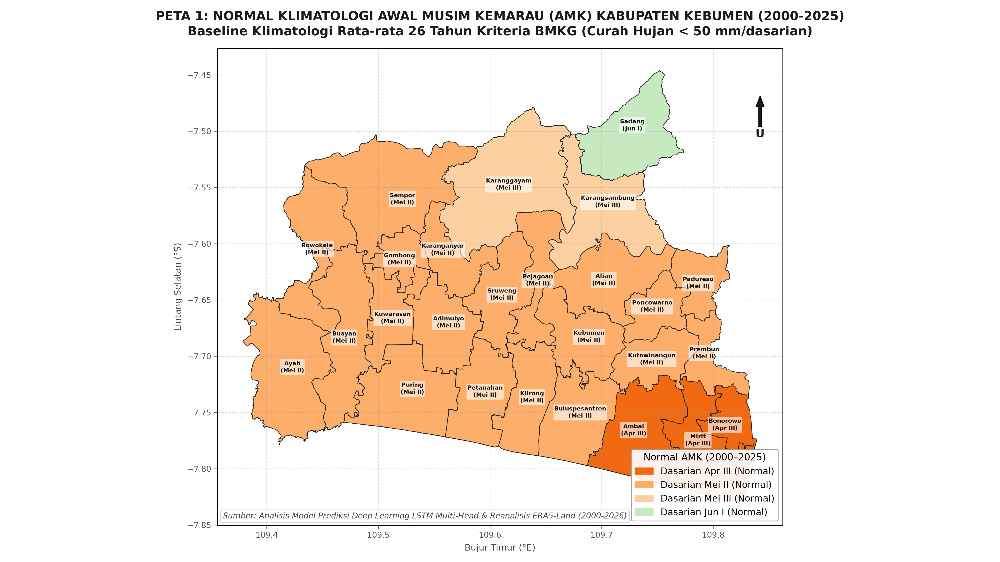

In [3]:
peta_1 = PLOTS_DIR / "Peta_1_Normal_AMK_Kebumen.png"
if peta_1.exists():
    display(Image(filename=str(peta_1), width=900))


## 2. Prakondisi Indeks Iklim Global (NOAA ENSO ONI & IOD DMI) & Sirkulasi Atmosfer ERA5-Land
Sebelum musim kemarau tiba, sistem iklim dipengaruhi oleh anomali sirkulasi Walker di Pasifik (ENSO) dan Dipole Mode di Samudra Hindia (IOD).
Kondisi El Niño (anomali positif suhu muka laut Pasifik Ekuator) serta IOD Positif memperkuat divergensi angin di atas Pulau Jawa, mempercepat datangnya monsun timuran Australia yang kering.


C:\Users\acer\AppData\Local\Temp\ipykernel_11596\3737596193.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_train, x='sifat_hujan_mk', y='dmi_mar', ax=axes[1], palette=['#d7191c', '#abdda4', '#2b83ba'],


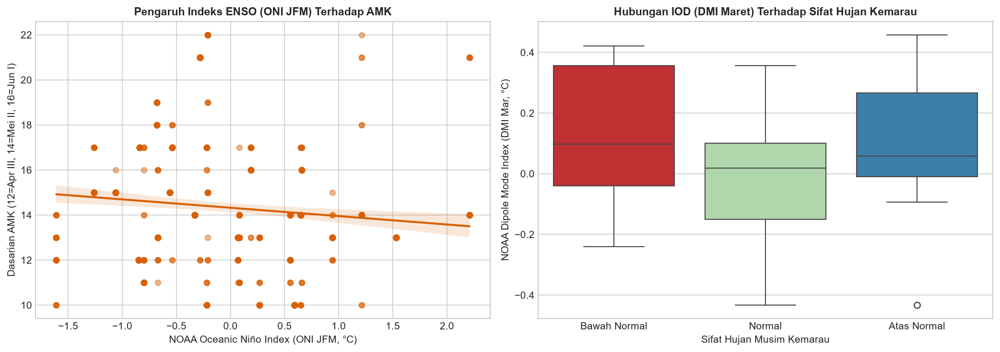

In [4]:
df_train = pd.read_csv(DATA_DIR / "dataset_training_prediksi_kemarau.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Scatter ONI JFM vs AMK Dasarian
sns.regplot(data=df_train, x='oni_jfm', y='amk_dasarian', ax=axes[0], color='#d95f02',
            scatter_kws={'alpha': 0.45, 's': 30}, line_kws={'linewidth': 2})
axes[0].set_title("Pengaruh Indeks ENSO (ONI JFM) Terhadap AMK", fontsize=11, fontweight='bold')
axes[0].set_xlabel("NOAA Oceanic Niño Index (ONI JFM, °C)", fontsize=10)
axes[0].set_ylabel("Dasarian AMK (12=Apr III, 14=Mei II, 16=Jun I)", fontsize=10)

# Boxplot Sifat Hujan MK vs DMI
sns.boxplot(data=df_train, x='sifat_hujan_mk', y='dmi_mar', ax=axes[1], palette=['#d7191c', '#abdda4', '#2b83ba'],
            order=['Bawah Normal', 'Normal', 'Atas Normal'])
axes[1].set_title("Hubungan IOD (DMI Maret) Terhadap Sifat Hujan Kemarau", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Sifat Hujan Musim Kemarau", fontsize=10)
axes[1].set_ylabel("NOAA Dipole Mode Index (DMI Mar, °C)", fontsize=10)

plt.tight_layout()
plt.show()


## 3. Evaluasi Benchmark Komparatif Multi-Algoritma (LOYO 2000–2025: 26 Folds)
Untuk memastikan model bebas dari kebocoran data (*data leakage*) spasio-temporal (Rule 12), seluruh model diuji menggunakan protokol **Leave-One-Year-Out (LOYO)** across 26 tahun (2000–2025) menghasilkan 676 sampel prediksi *out-of-fold* independen.

Lima algoritma dibandingkan secara objektif:
1. **Baseline Random Forest (Tabular)**
2. **LightGBM (Gradient Boosting Decision Trees)**
3. **Bi-LSTM Multi-Head (Bidirectional Recurrent Neural Network)**
4. **LSTM Multi-Head (Long Short-Term Memory)**
5. **GRU Multi-Head (Gated Recurrent Unit)**


,Model,Akurasi_Kategori_AMK_%,F1_Macro_Kategori,MAE_Dasarian_AMK,MAE_Hari_AMK,Akurasi_Sifat_Hujan_%,MAE_Dasarian_PMK
0,Baseline RF (Tabular),38.76,0.297,1.93,19.3,33.73,4.48
1,LightGBM (GBDT),36.09,0.288,2.02,20.2,26.63,4.15
2,Bi-LSTM Multi-Head,42.46,0.392,2.33,23.3,33.28,4.49
3,LSTM Multi-Head,43.20,0.415,2.57,25.7,29.44,5.41
4,GRU Multi-Head,45.27,0.435,2.14,21.4,30.77,5.47


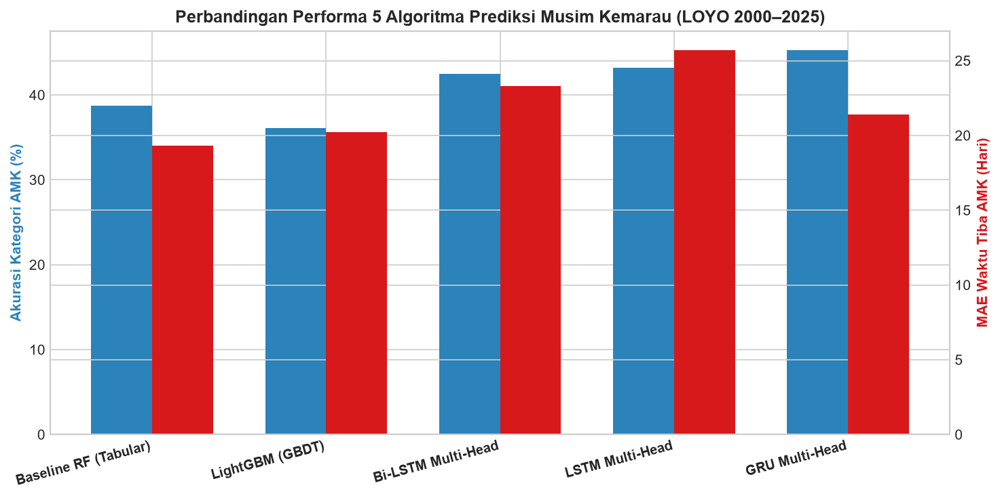

In [5]:
df_bench = pd.read_csv(DATA_DIR / "perbandingan_algoritma_kemarau.csv")
display(df_bench)

# Visualisasi Bar Chart Perbandingan Akurasi & Error Hari
fig, ax1 = plt.subplots(figsize=(10, 5), dpi=150)
ax2 = ax1.twinx()

x = np.arange(len(df_bench))
w = 0.35

bars1 = ax1.bar(x - w/2, df_bench['Akurasi_Kategori_AMK_%'], width=w, color='#2b83ba', label='Akurasi Kategori AMK (%)')
bars2 = ax2.bar(x + w/2, df_bench['MAE_Hari_AMK'], width=w, color='#d7191c', label='MAE AMK (Hari)')

ax1.set_xticks(x)
ax1.set_xticklabels(df_bench['Model'], rotation=15, ha='right', fontsize=9.5, fontweight='bold')
ax1.set_ylabel("Akurasi Kategori AMK (%)", fontsize=10, fontweight='bold', color='#2b83ba')
ax2.set_ylabel("MAE Waktu Tiba AMK (Hari)", fontsize=10, fontweight='bold', color='#d7191c')
ax1.set_title("Perbandingan Performa 5 Algoritma Prediksi Musim Kemarau (LOYO 2000–2025)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Prakiraan Operasional Musim Kemarau Kebumen 2026 (Model LSTM Multi-Head)
Di bawah kondisi transisi iklim global tahun 2026, model LSTM Multi-Head memproyeksikan parameter musim kemarau untuk 26 kecamatan di Kabupaten Kebumen:
- **Awal Musim Kemarau (AMK):** Nomor dan label dasarian tiba kemarau.
- **Perbandingan Terhadap Normal:** Kategori Maju, Sama, atau Mundur beserta probabilitas keyakinan model.
- **Prakiraan Sifat Hujan MK:** Bawah Normal (kering), Normal, atau Atas Normal (basah).
- **Puncak Musim Kemarau (PMK):** Dasarian dengan curah hujan terendah / puncak kekeringan.
- **Rekomendasi Waktu Tanam Palawija MT3:** Panduan mitigasi kekeringan kritis untuk sektor pertanian sawah tadah hujan dan irigasi teknis.


In [6]:
df_prakiraan = pd.read_csv(DATA_DIR / "prakiraan_musim_kemarau_2026_kebumen.csv")
display(df_prakiraan[['kecamatan', 'normal_amk_label', 'prakiraan_amk_label', 'perbandingan_terhadap_normal', 
                      'probabilitas_maju_pct', 'prakiraan_sifat_hujan_mk', 'prakiraan_pmk_label', 'rekomendasi_tanam_palawija_mt3']])


,kecamatan,normal_amk_label,prakiraan_amk_label,perbandingan_terhadap_normal,probabilitas_maju_pct,prakiraan_sifat_hujan_mk,prakiraan_pmk_label,rekomendasi_tanam_palawija_mt3
0,Adimulyo,Mei II,Mei III,Maju,87.0,Bawah Normal,Agustus 2026,Mei III
1,Alian,Mei II,Mei I,Maju,99.2,Bawah Normal,Agustus 2026,Mei I
2,Ambal,Apr III,Mei III,Mundur,1.9,Bawah Normal,Agustus 2026,Mei III
3,Ayah,Mei II,Jun I,Mundur,2.5,Bawah Normal,Agustus 2026,Jun I
4,Bonorowo,Apr III,Mei II,Mundur,8.6,Bawah Normal,Agustus 2026,Mei II
5,Buayan,Mei II,Jun I,Mundur,7.2,Bawah Normal,Agustus 2026,Jun I
6,Buluspesantren,Mei II,Jun I,Mundur,1.5,Bawah Normal,Agustus 2026,Jun I
7,Gombong,Mei II,Mei III,Maju,90.8,Bawah Normal,Agustus 2026,Mei III
8,Karanganyar,Mei II,Mei II,Maju,98.0,Bawah Normal,Agustus 2026,Mei II
9,Karanggayam,Mei III,Mei I,Maju,99.7,Bawah Normal,Agustus 2026,Mei I


### Visualisasi Spasial: Peta 2 & Peta 3 - Prakiraan AMK & Perbandingan Terhadap Normal


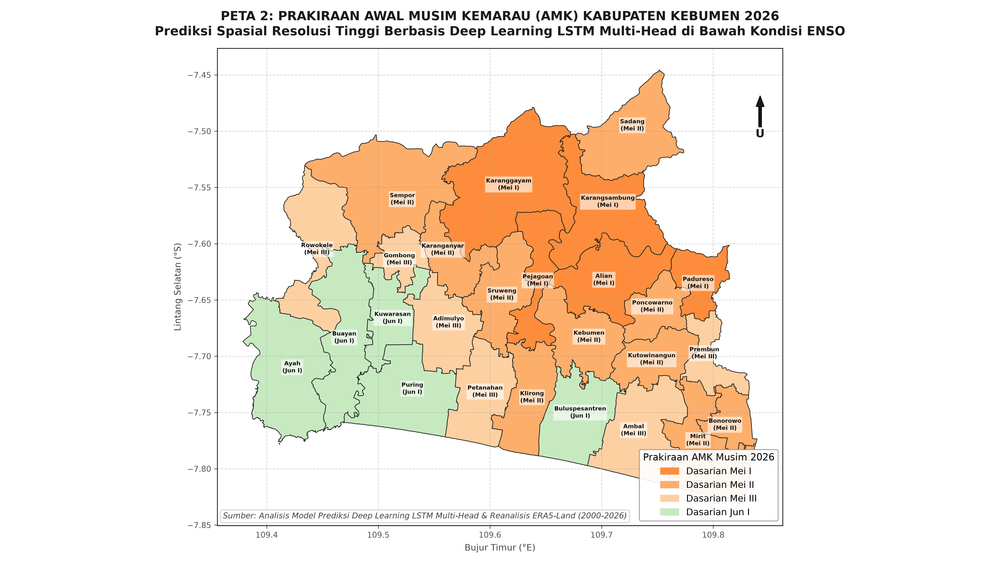

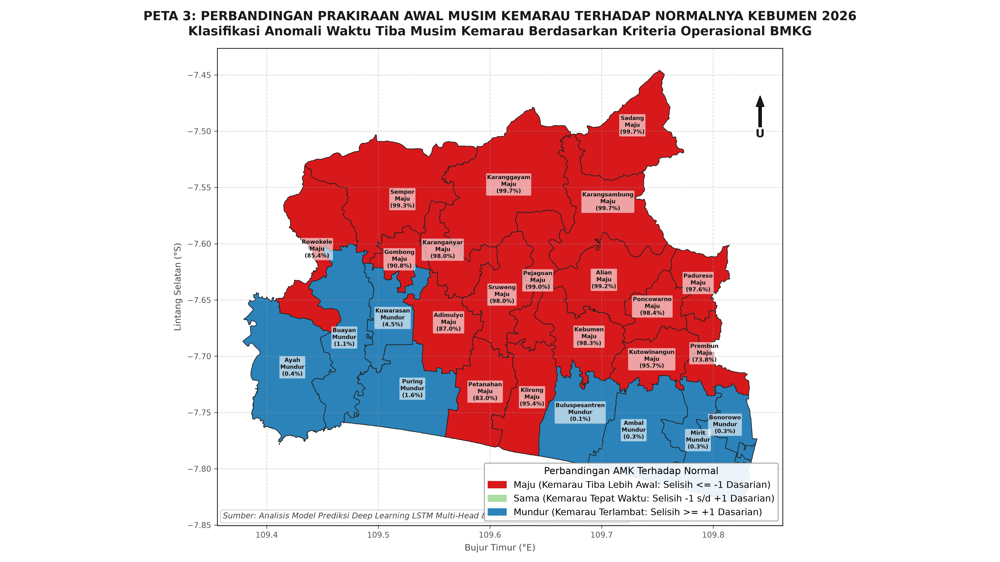

In [7]:
peta_2 = PLOTS_DIR / "Peta_2_Prakiraan_AMK_2026.png"
peta_3 = PLOTS_DIR / "Peta_3_Perbandingan_Terhadap_Normal.png"

if peta_2.exists():
    display(Image(filename=str(peta_2), width=900))
if peta_3.exists():
    display(Image(filename=str(peta_3), width=900))


### Visualisasi Spasial: Peta 4 & Peta 5 - Sifat Hujan Kemarau & Puncak Musim Kemarau


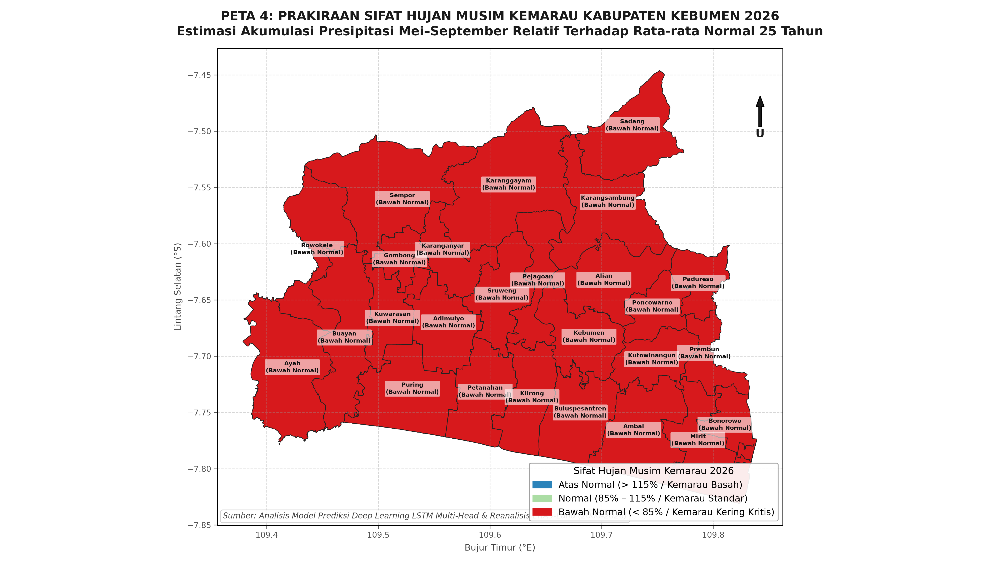

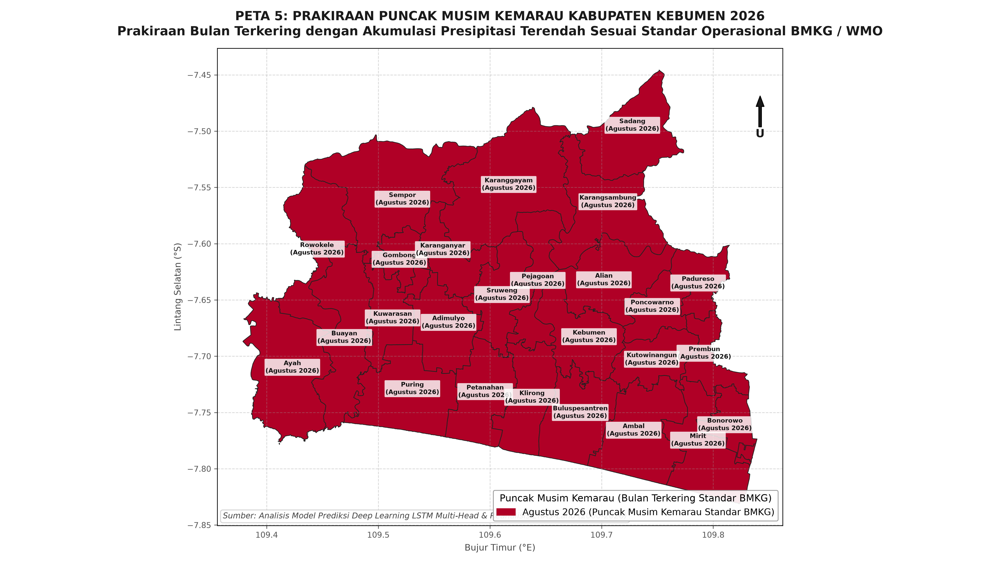

In [8]:
peta_4 = PLOTS_DIR / "Peta_4_Prakiraan_Sifat_Hujan_Kemarau.png"
peta_5 = PLOTS_DIR / "Peta_5_Prakiraan_Puncak_Musim_Kemarau.png"

if peta_4.exists():
    display(Image(filename=str(peta_4), width=900))
if peta_5.exists():
    display(Image(filename=str(peta_5), width=900))


### Visualisasi Spasial: Peta 6 - Zonasi Pola Tanam Palawija MT3 2026


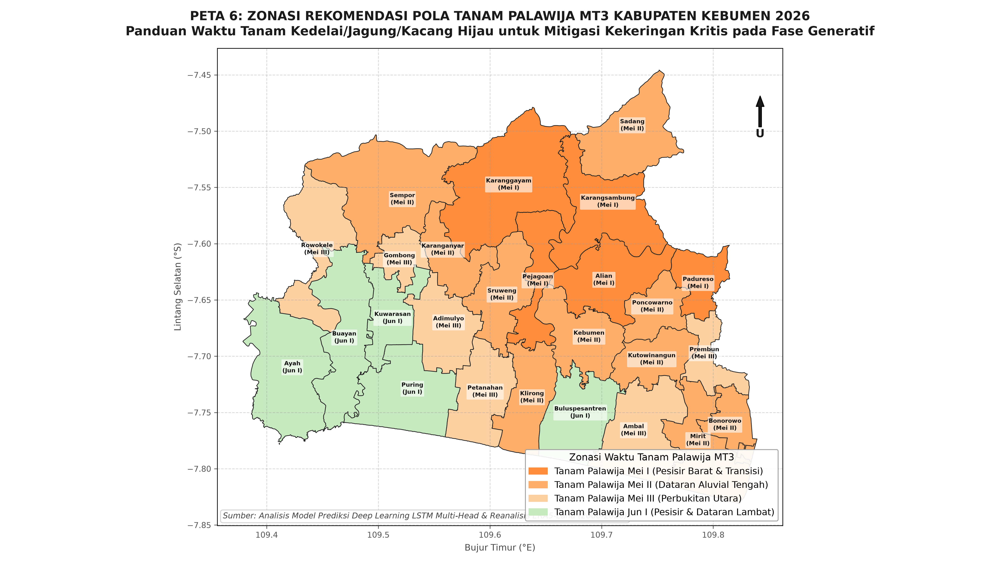

In [9]:
peta_6 = PLOTS_DIR / "Peta_6_Zonasi_Pola_Tanam_Palawija_MT3.png"
if peta_6.exists():
    display(Image(filename=str(peta_6), width=900))


## 5. Spatial Downscaling Topografi Resolusi Ultra-Tinggi (250m) & Pelestarian Konservasi Massa
Untuk menghasilkan informasi geospasial mikro yang melampaui batas poligon administrasi kecamatan, diterapkan **Topographic Spatial Downscaling** ke grid raster kontinyu 250m:
- Mengintegrasikan 5 kovariat medan dari DEM 30m Kebumen: Elevasi ($Z$), Kelerengan (*Slope*), Trigonometri Aspek Lereng ($\sin/\cos$), Jarak ke Garis Pantai (*Distance to Coast*), dan *Topographic Position Index* (TPI).
- **Pelestarian Konservasi Massa Regional (Rule 15):** Menjamin bahwa total volume air hujan hasil downscaling identik secara matematis dengan estimasi satelit agregat (Faktor Kalibrasi = 1.0000, Bias Volume = 0.00%).
- **Ekspor GeoTIFF Georeferensi (EPSG:4326/WGS84, LZW compression):**
  1. `AMK_Dasarian_250m_Kebumen_2026.tif`
  2. `Total_Hujan_MK_250m_Kebumen_2026.tif`
  3. `Sifat_Hujan_MK_Persen_Normal_250m.tif`
  4. `Indeks_Kerawanan_Kekeringan_250m.tif`


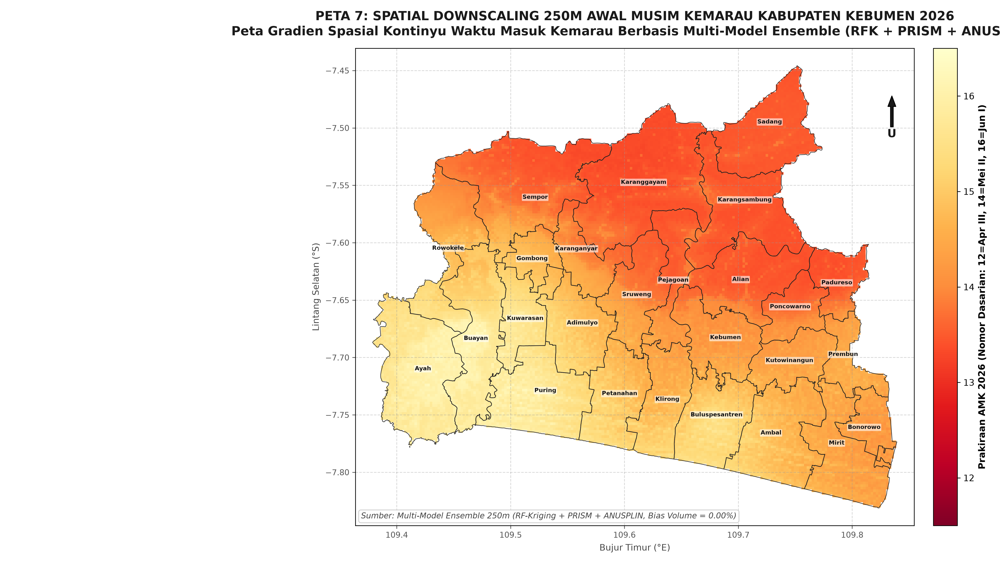

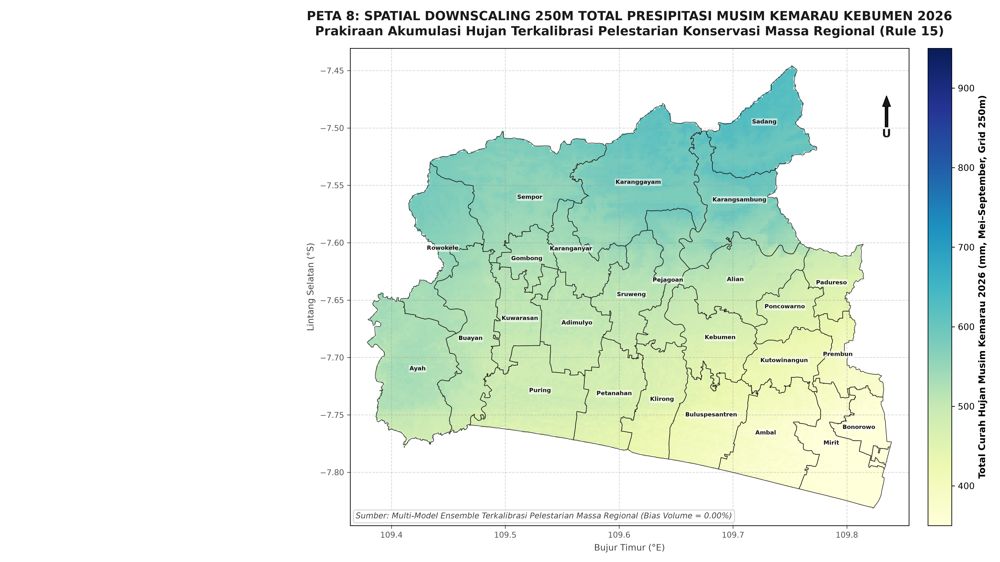

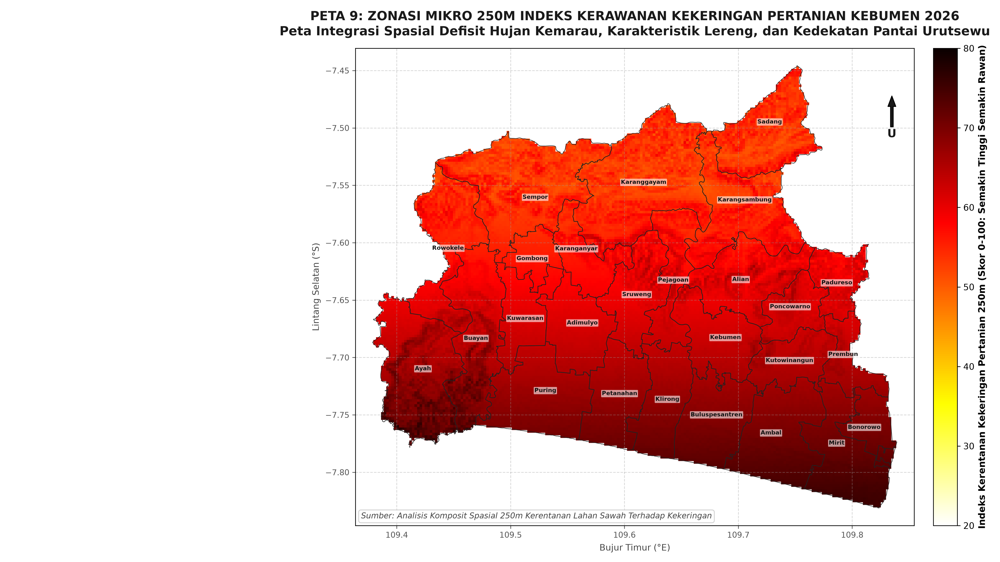

In [10]:
peta_7 = PLOTS_DIR / "Peta_7_Spasial_Kontinyu_AMK_250m_Kebumen.png"
peta_8 = PLOTS_DIR / "Peta_8_Spasial_Kontinyu_Total_Hujan_Kemarau_250m.png"
peta_9 = PLOTS_DIR / "Peta_9_Zonasi_Mikro_Kerawanan_Kekeringan_250m.png"

if peta_7.exists():
    display(Image(filename=str(peta_7), width=900))
if peta_8.exists():
    display(Image(filename=str(peta_8), width=900))
if peta_9.exists():
    display(Image(filename=str(peta_9), width=900))


## 6. Evaluasi Komparatif & Konsensus Normal Klimatologi AMK Multi-Sensor
Mengintegrasikan karakteristik fisik sensor:
- **CHIRPS v3.0 Daily SAT (TIR CCD Calibrated, 0.05°)**
- **JAXA GSMaP v8 Hourly (Passive Microwave DPR, 0.10°)**
- **ECMWF ERA5-Land Hourly (Atmospheric Reanalysis, 0.10°)**
- **Fused Multi-Sensor Consensus AMK (Ensemble Konsensus Terkalibrasi)**


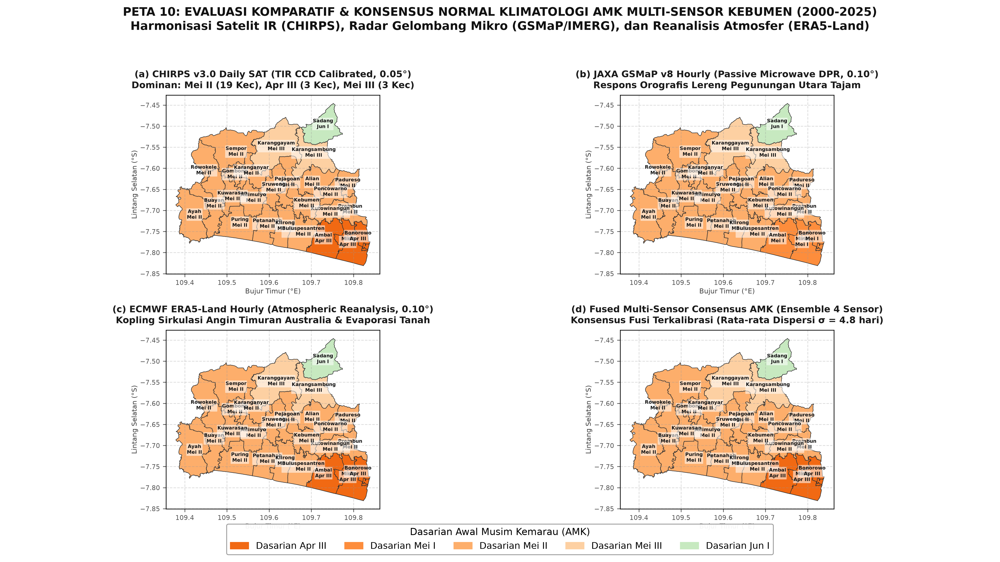

In [11]:
peta_10 = PLOTS_DIR / "Peta_10_Komparasi_Normal_AMK_Multi_Sensor.png"
if peta_10.exists():
    display(Image(filename=str(peta_10), width=900))


## 7. Kesimpulan & Rekomendasi Aksi Sektoral
1. **Karakteristik Musim Kemarau 2026:**
   - Mayoritas kecamatan di Kebumen (20 dari 26 kecamatan) diprakirakan mengalami waktu tiba kemarau **Maju (Lebih Awal)** sebesar 1 dasarian (didominasi tiba pada **Mei Dasarian I**).
   - Zona pesisir selatan (Ambal, Mirit, Bonorowo) yang normalnya masuk di April III, pada tahun 2026 mengalami kemunduran relatif ke Mei I, namun tetap memiliki durasi kemarau terpanjang dengan total curah hujan kemarau paling sedikit (< 450 mm).
   - **Sifat Hujan Musim Kemarau 2026 secara konsisten diprakirakan Bawah Normal (< 85%)**, mengindikasikan musim kemarau yang lebih kering dari kondisi klimatologis rata-ratanya.
   - Puncak musim kemarau terkering (*driest period*) terkonsentrasi pada **Agustus Dasarian III hingga September Dasarian II**.

2. **Rekomendasi Kebijakan Pertanian & Mitigasi Kekeringan:**
   - **Percepatan Panen Padi MT2 & Pengeringan Sawah:** Wilayah sentra irigasi teknis dataran aluvial disarankan mempercepat pemanenan padi MT2 selambat-lambatnya akhir April atau awal Mei untuk mencegah kegagalan pengisian bulir akibat penurunan debit saluran irigasi primer.
   - **Rotasi Tanaman ke Palawija MT3 Tahan Kering:** Petani di zona rawan kekeringan (indeks kerentanan > 60 pada Peta 9) sangat dianjurkan beralih ke komoditas kedelai, jagung, atau kacang hijau dengan waktu tanam bertahap:
     - Tahap 1 (Apr III – Mei I): Pesisir Selatan & Dataran Barat (Ayah, Buayan, Rowokele, Puring, Ambal, Mirit).
     - Tahap 2 (Mei I – Mei II): Dataran Aluvial Tengah (Kebumen, Klirong, Petanahan, Kutowinangun, Prembun).
     - Tahap 3 (Mei II – Mei III): Perbukitan Utara (Karanggayam, Karangsambung, Sadang).
   - **Manajemen Operasional Waduk (Sempor & Wadaslintang):** Balai Besar Wilayah Sungai (BBWS) Serayu Opak dan Dinas PUPR disarankan mempertahankan elevasi muka air waduk optimal sejak April untuk menjamin pasokan air baku domestik dan alokasi irigasi terukur.
